# Workshop 3 — Exploratory Data Analysis for Tsunami Monitoring

## 1. Data Preparation and Overview

Which observations are available for studying historical tsunami heights, annual coverage, and earthquake magnitudes? This notebook follows the profiling, univariate and bivariate stages in Carlos Andrés Sierra's *Data Engineering and Visualization* (PDF pp. 14, 23). It uses saved Silver and Gold results to investigate these questions.

Silver preserves snapshots from multiple runs. Topic folders contain the Workshop 3 snapshots, and the flat Parquet files at the Silver root contain older Workshop 2 snapshots. The published Gold pair consolidates both layouts by `(source, external_id)`. That key identifies an observation in one source. FDSN and Realtime can both report the same physical earthquake.

NOAA HazEL and USGS FDSN supply historical observations. USGS Realtime supplies a rolling earthquake feed, and NTWC and PTWC contribute CAP bulletins from saved feed captures. The overview uses the latest complete Gold pair when available. The NOAA measurements for the exploratory analyses come from the available Silver snapshots, whose refresh may differ from Gold.

In [13]:
%matplotlib inline

import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

silver_root = project_root / os.environ.get("SILVER_DIR", "datalake_silver")
gold_root = project_root / os.environ.get("GOLD_DIR", "datalake_gold")
topics = ("earthquakes", "tsunami_events", "tsunami_bulletins", "rejected_records")
key = ["source", "external_id"]
source_names = {
    "noaa_hazel": "NOAA HazEL",
    "usgs_fdsn": "USGS FDSN",
    "usgs_realtime": "USGS Realtime",
    "ntwc": "NTWC",
    "ptwc": "PTWC",
}
teal, orange = "#167c80", "#b65a2c"

In [14]:
def complete_parquet(path):
    return path.is_file() or ((path / "_SUCCESS").is_file() and any(path.glob("part-*.parquet")))


governance = storytelling = None
gold_stamp = None
for candidate in sorted(gold_root.glob("governance_*.parquet"), reverse=True):
    stamp = candidate.stem.removeprefix("governance_")
    companion = gold_root / f"storytelling_{stamp}.parquet"
    if re.fullmatch(r"\d{8}_\d{6}", stamp) and complete_parquet(candidate) and complete_parquet(companion):
        governance = pd.read_parquet(candidate, dtype_backend="numpy_nullable")
        storytelling = pd.read_parquet(companion, dtype_backend="numpy_nullable")
        gold_stamp = stamp
        break

if gold_stamp:
    print(f"Gold pair {gold_stamp} (UTC) under {gold_root}")
else:
    print(f"No complete Gold pair under {gold_root}. The overview uses Silver and the Gold heatmap is unavailable.")

Gold pair 20261120_060020 (UTC) under /home/linmonp/tsunami-monitoring/datalake_gold


### Selecting NOAA records for analysis

The height and magnitude values are available at row level in Silver. Read the needed fields from both Silver layouts with pandas. For a NOAA identifier that occurs in several snapshots, select the row with the latest Bronze capture stamp. Silver processing time and the filename stamp provide fallbacks, with processing time and source path breaking remaining ties. This follows the NOAA ordering in `src/gold.py` for Silver snapshots that already have one row per key within each file. The date and clock fields keep their original precision.

In [15]:
def discover_silver(root):
    return {
        topic: sorted(path for folder in (root, root / topic)
                      for path in folder.glob(f"{topic}_*.parquet") if path.is_file())
        for topic in topics
    }


silver_files = discover_silver(silver_root)
if not any(silver_files.values()) and "SILVER_DIR" not in os.environ:
    silver_root = silver_root / "samples"
    silver_files = discover_silver(silver_root)


def read_silver(topic, columns):
    batches = []
    for path in silver_files[topic]:
        batch = pd.read_parquet(path, columns=columns, dtype_backend="numpy_nullable")
        if not batch.empty:
            batches.append(batch.assign(snapshot_path=path.resolve().as_uri()))
    return pd.concat(batches, ignore_index=True) if batches else pd.DataFrame(columns=[*columns, "snapshot_path"])


noaa_columns = key + [
    "event_date", "event_time", "time_precision", "latitude", "longitude",
    "max_water_height", "reported_eq_magnitude", "cause_code", "event_validity",
    "location_name", "bronze_manifest", "silver_processed_at",
]
noaa_snapshots = read_silver("tsunami_events", noaa_columns)
noaa_snapshots = noaa_snapshots.loc[noaa_snapshots["source"].eq("noaa_hazel")]

stamp_format = "%Y%m%d_%H%M%S"
bronze_stamp = noaa_snapshots["bronze_manifest"].str.extract(r"^bronze_manifest_(\d{8}_\d{6})(?:_|\.)", expand=False)
filename_stamp = noaa_snapshots["snapshot_path"].str.extract(r"_(\d{8}_\d{6})\.parquet$", expand=False)
processed = pd.to_datetime(noaa_snapshots["silver_processed_at"], utc=True, errors="coerce")
captured = pd.to_datetime(bronze_stamp, format=stamp_format, utc=True, errors="coerce")
captured = captured.fillna(processed).fillna(
    pd.to_datetime(filename_stamp, format=stamp_format, utc=True, errors="coerce")
)
noaa = (noaa_snapshots.assign(captured_at=captured, processed_at=processed)
        .sort_values(["captured_at", "processed_at", "snapshot_path"], kind="stable", na_position="first")
        .drop_duplicates(key, keep="last").reset_index(drop=True))

flat_count = sum(path.parent == silver_root for files in silver_files.values() for path in files)
topic_count = sum(map(len, silver_files.values())) - flat_count
print(f"Silver input {silver_root} includes {topic_count} topic snapshots and {flat_count} flat archives.")
print(f"NOAA row-level analysis reads {len(silver_files['tsunami_events'])} Silver snapshots.")

Silver input /home/linmonp/tsunami-monitoring/datalake_silver includes 23 topic snapshots and 4 flat archives.
NOAA row-level analysis reads 3 Silver snapshots.


In [16]:
if governance is not None:
    source_counts = governance.loc[governance["topic"].ne("rejected_records")]
    count_basis = "published Gold pair"
else:
    batches = [noaa_snapshots, read_silver("earthquakes", key), read_silver("tsunami_bulletins", key)]
    available_keys = [batch[key] for batch in batches if not batch.empty]
    keys = pd.concat(available_keys, ignore_index=True) if available_keys else pd.DataFrame(columns=key)
    source_counts = keys.groupby("source")["external_id"].agg(
        rows_processed="size", unique_observations="nunique"
    ).reset_index()
    source_counts["repeated_rows"] = source_counts["rows_processed"] - source_counts["unique_observations"]
    count_basis = "selected Silver snapshots"

if source_counts.empty:
    print("No observation records were found in the selected input.")
else:
    overview = source_counts.set_index("source")["unique_observations"].rename(index=source_names)
    display(overview.rename_axis("Source").rename("Unique observations").sort_values(ascending=False).to_frame())
    print(f"Coverage is measured from the {count_basis}.")

,Unique observations
Source,
USGS FDSN,1929
USGS Realtime,759
NOAA HazEL,221
PTWC,2
NTWC,1


Coverage is measured from the published Gold pair.


## 2. Data Quality Assessment

Can the observed fields support geographic, temporal and quantitative analysis? Apply completeness, uniqueness and validity as taught on PDF pp. 23, 26 and 31. The missing-value rates below use current NOAA observations. Processing and rejection counts use the identified Gold pair, with a Silver fallback when that pair is unavailable. The normalized coordinate bounds are latitude from −90° to 90° and longitude from −180° to 180°.

A repeated source key can represent either another capture or a revision. Rejection occurrences count processing outcomes. Distinct rejections group the source, external ID, Bronze file, row locator and reason. Missing heights and clock components retain their meaning as missing measurements.

In [17]:
quality_rows = []


def frequency(count, total):
    return f"{count:,}/{total:,} ({count / total:.2%})"


height = noaa["max_water_height"].astype(float)
height = height.where(np.isfinite(height))
magnitude = noaa["reported_eq_magnitude"].astype(float)
magnitude = magnitude.where(np.isfinite(magnitude))
missing_time = noaa["event_time"].isna()

if not noaa.empty:
    n = len(noaa)
    missing_coordinates = noaa[["latitude", "longitude"]].isna().any(axis=1)
    outside_bounds = (
        (noaa["latitude"].notna() & ~noaa["latitude"].between(-90, 90))
        | (noaa["longitude"].notna() & ~noaa["longitude"].between(-180, 180))
    )
    quality_rows.extend([
        ("Completeness", "NOAA has a missing coordinate", frequency(missing_coordinates.sum(), n),
         "Preserve null coordinates", "Spatial matching needs both coordinates."),
        ("Completeness", "NOAA lacks a full timestamp", frequency(missing_time.sum(), n),
         "Keep recorded date and clock precision", "Dated records support yearly counts and interval-based matching."),
        ("Completeness", "NOAA has no finite maximum water height", frequency(height.isna().sum(), n),
         "Use measured values for height summaries", "Height coverage is smaller than catalog coverage."),
        ("Validity", "NOAA coordinate outside normalized bounds", frequency(outside_bounds.sum(), n),
         "Check normalized latitude and longitude", "A range check can detect invalid coordinates in the Silver output."),
    ])

if not source_counts.empty:
    totals = source_counts[["rows_processed", "unique_observations", "repeated_rows"]].sum().astype(int)
    volume = (f"{totals.rows_processed:,} processed, {totals.unique_observations:,} unique, "
              f"{totals.repeated_rows:,} repeated")
    quality_rows.append(("Uniqueness", f"Observation volume in {count_basis}", volume,
                         "Select one version per source key", "Repeated captures and revisions contribute to processing volume."))

if governance is not None:
    rejections = governance.loc[governance["topic"].eq("rejected_records")]
    processed_rejections = int(rejections["rejected_records"].sum())
    distinct_rejections = (int(rejections["unique_rejected_records"].sum())
                           if "unique_rejected_records" in rejections.columns else None)
else:
    rejection_key = key + ["bronze_file", "locator", "reason"]
    rejected = read_silver("rejected_records", rejection_key)
    processed_rejections = len(rejected)
    distinct_rejections = len(rejected.drop_duplicates(rejection_key))

if governance is not None or silver_files["rejected_records"]:
    distinct_text = f"{distinct_rejections:,} distinct" if distinct_rejections is not None else "distinct count unavailable"
    quality_rows.append(("Validity", f"Rejections in {count_basis}",
                         f"{processed_rejections:,} occurrences, {distinct_text}",
                         "Quarantine with the Bronze reference", "Repeated processing can record the same rejection again."))

bulletins = read_silver("tsunami_bulletins", key + ["expires_before_sent"])
if not bulletins.empty:
    flagged = bulletins.loc[bulletins["expires_before_sent"].fillna(False), key].drop_duplicates()
    bulletin_keys = bulletins[key].drop_duplicates()
    quality_rows.append(("Validity", "CAP expiry before issue in saved Silver snapshots",
                         frequency(len(flagged), len(bulletin_keys)),
                         "Retain the original times and Silver flag", "Flagged expiry fields need review before using them."))

if quality_rows:
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(quality_rows, columns=["Dimension", "Finding", "Frequency", "Treatment", "Implication"]))

if missing_time.any():
    partial = noaa.loc[missing_time, "time_precision"].fillna("unreported").value_counts()
    print("Precision among NOAA observations without a full timestamp — " +
          ", ".join(f"{label} {count}" for label, count in partial.items()) + ".")

,Dimension,Finding,Frequency,Treatment,Implication
0,Completeness,NOAA has a missing coordinate,9/221 (4.07%),Preserve null coordinates,Spatial matching needs both coordinates.
1,Completeness,NOAA lacks a full timestamp,32/221 (14.48%),Keep recorded date and clock precision,Dated records support yearly counts and interval-based matching.
2,Completeness,NOAA has no finite maximum water height,12/221 (5.43%),Use measured values for height summaries,Height coverage is smaller than catalog coverage.
3,Validity,NOAA coordinate outside normalized bounds,0/221 (0.00%),Check normalized latitude and longitude,A range check can detect invalid coordinates in the Silver output.
4,Uniqueness,Observation volume in published Gold pair,"15,632 processed, 2,912 unique, 12,720 repeated",Select one version per source key,Repeated captures and revisions contribute to processing volume.
5,Validity,Rejections in published Gold pair,"2 occurrences, 1 distinct",Quarantine with the Bronze reference,Repeated processing can record the same rejection again.
6,Validity,CAP expiry before issue in saved Silver snapshots,1/3 (33.33%),Retain the original times and Silver flag,Flagged expiry fields need review before using them.


Precision among NOAA observations without a full timestamp — day 23, minute 9.


In [ ]:
# Uniqueness per source: Silver keeps every run, so a key repeats once per snapshot that contains it
dup_rows = []
for topic in ("earthquakes", "tsunami_events", "tsunami_bulletins"):
    keys = read_silver(topic, key)
    for source, group in keys.groupby("source"):
        rows, unique = len(group), group["external_id"].nunique()
        dup_rows.append((topic, source_names.get(source, source), group["snapshot_path"].nunique(), rows, unique,
                         rows - unique, round(100 * (rows - unique) / rows, 2) if rows else 0.0))
duplicate_rate = pd.DataFrame(dup_rows, columns=["Topic", "Source", "Snapshots", "Silver rows", "Unique keys",
                                                 "Repeated rows", "Duplicate rate before (%)"])
duplicate_rate["Duplicate rate after (%)"] = 0.0  # one row per key after selecting the current version
display(duplicate_rate)
print("Each Silver snapshot is internally unique; the repetition comes from keeping every run. "
      "Gold selects one current version per key, so the rate after consolidation is zero by construction.")

## 3. Descriptive Statistics of Tsunami Heights

What is a typical reported maximum water height, and how large is the upper tail? Summarize the finite `max_water_height` measurements from the selected NOAA observations. The boxplot shows the median, quartiles and points beyond the 1.5 IQR fences (PDF pp. 16–19, 27–30 and 48). The axis is linear up to 1 m and compressed above it to show the central spread and the largest measurements together. Calculations use the original values in metres.

,Value
Available heights,209.00
Mean (m),6.42
Median (m),0.20
Minimum (m),0.00
Maximum (m),481.00
Sample standard deviation (m),38.36
First quartile Q1 (m),0.08
Third quartile Q3 (m),0.70
IQR (m),0.62


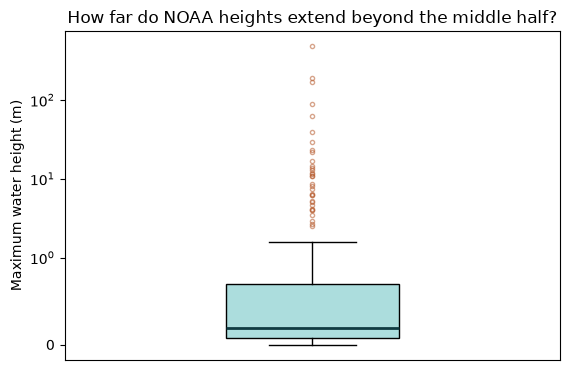

The middle half of reported heights spans 0.08 to 0.70 m (IQR 0.62 m). The mean is 6.42 m and the median is 0.20 m.
33 observations exceed the upper IQR fence. The largest height is 481.00 m at TRACY ARM, AK (NOAA 6045). An IQR flag identifies a value for review. The summary retains all finite values.


In [18]:
heights = height.dropna()
if heights.empty:
    print("The selected NOAA records contain no finite water heights.")
else:
    q1, q3 = heights.quantile([0.25, 0.75])
    iqr = q3 - q1
    height_stats = pd.Series({
        "Available heights": len(heights),
        "Mean (m)": heights.mean(),
        "Median (m)": heights.median(),
        "Minimum (m)": heights.min(),
        "Maximum (m)": heights.max(),
        "Sample standard deviation (m)": heights.std(),
        "First quartile Q1 (m)": q1,
        "Third quartile Q3 (m)": q3,
        "IQR (m)": iqr,
    }, name="Value")
    display(height_stats.round(2).to_frame())

    fig, ax = plt.subplots(figsize=(5.8, 3.8))
    ax.boxplot(heights, widths=0.35, patch_artist=True, boxprops={"facecolor": "#acdddd"},
               medianprops={"color": "#103b42", "linewidth": 2},
               flierprops={"marker": "o", "markersize": 3, "alpha": 0.55, "markeredgecolor": orange})
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xticks([])
    ax.set(ylabel="Maximum water height (m)", title="How far do NOAA heights extend beyond the middle half?")
    fig.tight_layout()
    plt.show()

    upper_fliers = heights.gt(q3 + 1.5 * iqr).sum()
    largest = noaa.loc[heights.idxmax()]
    print(f"The middle half of reported heights spans {q1:.2f} to {q3:.2f} m (IQR {iqr:.2f} m). "
          f"The mean is {heights.mean():.2f} m and the median is {heights.median():.2f} m.")
    print(f"{upper_fliers} observations exceed the upper IQR fence. The largest height is "
          f"{heights.max():.2f} m at {largest['location_name']} (NOAA {largest['external_id']}). "
          "An IQR flag identifies a value for review. The summary retains all finite values.")

## 4. Temporal Analysis of Historical Tsunamis

Which years have the most NOAA observations in the queried catalog? Count the selected observations by their recorded calendar year from 2010 through 2025. Dates with incomplete clock information still contribute. The line makes year-to-year differences in observed volume visible (PDF pp. 49–51). These counts reflect the queried HazEL coverage.

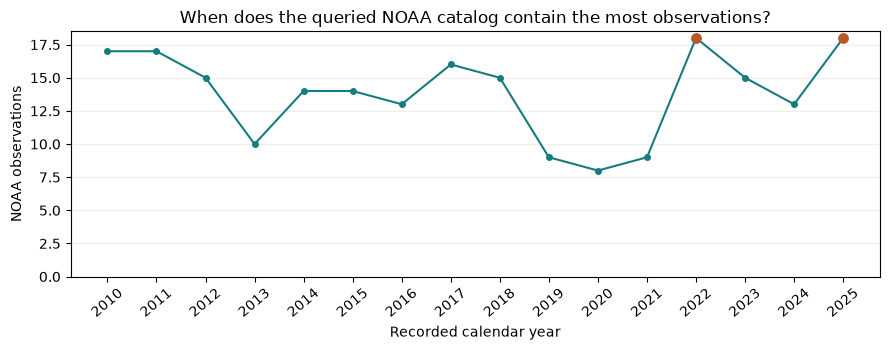

Annual counts range from 8 to 18 across the selected period. The highest count occurs in 2022, 2025 (18 per year).


In [19]:
calendar_year = pd.to_datetime(noaa["event_date"], errors="coerce").dt.year
scope = calendar_year.between(2010, 2025)
if scope.any():
    annual = calendar_year[scope].value_counts().reindex(range(2010, 2026), fill_value=0)
    peaks = annual[annual.eq(annual.max())]

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(annual.index, annual, color=teal, marker="o", markersize=4)
    ax.scatter(peaks.index, peaks, color=orange, s=46, zorder=3)
    ax.set_xticks(annual.index)
    ax.tick_params(axis="x", labelrotation=40)
    ax.set(xlabel="Recorded calendar year", ylabel="NOAA observations",
           title="When does the queried NOAA catalog contain the most observations?", ylim=(0, None))
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()

    peak_years = ", ".join(map(str, peaks.index))
    print(f"Annual counts range from {annual.min()} to {annual.max()} across the selected period. "
          f"The highest count occurs in {peak_years} ({annual.max()} per year).")
else:
    print("The selected NOAA observations have no recorded dates in 2010–2025.")

In [ ]:
# The same yearly view for the earthquake catalog (USGS FDSN, M >= 6), next to the NOAA counts
fdsn = read_silver("earthquakes", key + ["event_time", "magnitude"])
fdsn = fdsn.loc[fdsn["source"].eq("usgs_fdsn")].drop_duplicates(key)
if fdsn.empty:
    print("No USGS FDSN observations in the selected Silver snapshots.")
else:
    eq_year = pd.to_datetime(fdsn["event_time"], utc=True, errors="coerce").dt.year
    eq_annual = eq_year[eq_year.between(2010, 2025)].value_counts().reindex(range(2010, 2026), fill_value=0)
    big = fdsn.loc[fdsn["magnitude"].astype(float) >= 7.0]
    big_annual = (pd.to_datetime(big["event_time"], utc=True).dt.year.value_counts()
                  .reindex(range(2010, 2026), fill_value=0))
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.bar(eq_annual.index, eq_annual.values, color=teal, label="M ≥ 6")
    ax.bar(big_annual.index, big_annual.values, color=orange, label="M ≥ 7")
    ax.set(xlabel="Year", ylabel="Earthquakes", title="USGS FDSN earthquakes per year in the Pacific query area")
    ax.legend()
    plt.tight_layout()
    plt.show()
    ratio = (annual / eq_annual).dropna() if "annual" in globals() else None
    print(f"M ≥ 6 per year: {eq_annual.min()}–{eq_annual.max()} (median {eq_annual.median():.0f}); "
          f"M ≥ 7: {big_annual.min()}–{big_annual.max()}.")
    if ratio is not None and not ratio.empty:
        print(f"NOAA tsunami observations per M ≥ 6 earthquake range from {ratio.min():.2f} to {ratio.max():.2f} "
              "by year; both catalogs use different selections, so this ratio is descriptive only.")

## 5. Earthquake Magnitude Analysis

Which magnitudes and reported magnitude types dominate each catalog? The heatmap reads the magnitude distribution from Gold Storytelling and shows counts for each source, reported type and half-open 0.5-wide bin (PDF pp. 49–52). Blank cells represent zero observations in the combination. The FDSN historical query uses a Pacific bounding box and a minimum magnitude of 6.0. Realtime uses a rolling 30-day feed with a 4.5 threshold and the saved captures extend its observed coverage. Their count distributions reflect these different selections. Comparing seismic activity would require comparable windows, coverage and magnitude criteria.

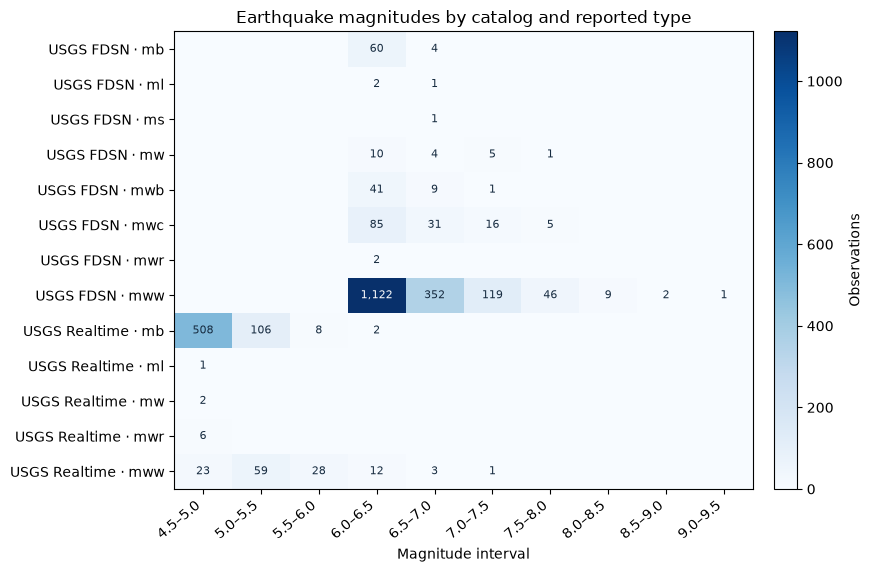

USGS FDSN has 1,122 mww observations in [6.0, 6.5), its largest count for a type and interval.
USGS Realtime has 508 mb observations in [4.5, 5.0), its largest count for a type and interval.


In [20]:
if storytelling is not None:
    magnitudes = storytelling.loc[storytelling["metric"].eq("earthquake_magnitude_distribution")].copy()
    if not magnitudes.empty:
        magnitudes["source"] = magnitudes["source"].replace(source_names)
        magnitudes["magnitude_type"] = magnitudes["magnitude_type"].fillna("Unreported")
        magnitude_grid = magnitudes.pivot(
            index=["source", "magnitude_type"], columns=["bin_start", "bin_end"], values="count"
        ).sort_index(axis=1).fillna(0)
        values = magnitude_grid.to_numpy(dtype=int)

        fig, ax = plt.subplots(figsize=(9, max(3, 0.34 * len(magnitude_grid) + 1.4)))
        image = ax.imshow(values, cmap="Blues", aspect="auto", vmin=0)
        ax.set_xticks(
            range(len(magnitude_grid.columns)),
            [f"{lower:.1f}–{upper:.1f}" for lower, upper in magnitude_grid.columns],
            rotation=40, ha="right",
        )
        ax.set_yticks(
            range(len(magnitude_grid.index)),
            [f"{source} · {scale}" for source, scale in magnitude_grid.index],
        )
        ax.set(xlabel="Magnitude interval", title="Earthquake magnitudes by catalog and reported type")
        for row, counts in enumerate(values):
            for column, count in enumerate(counts):
                if count:
                    color = "white" if image.norm(count) > 0.55 else "#162b40"
                    ax.text(column, row, f"{count:,}", ha="center", va="center", fontsize=8, color=color)
        fig.colorbar(image, ax=ax, label="Observations", pad=0.03)
        fig.tight_layout()
        plt.show()

        peaks = magnitudes.loc[magnitudes.groupby("source")["count"].idxmax()]
        for row in peaks.sort_values("source").itertuples(index=False):
            print(f"{row.source} has {row.count:,} {row.magnitude_type} observations in "
                  f"[{row.bin_start:.1f}, {row.bin_end:.1f}), its largest count for a type and interval.")

## 6. Bivariate Analysis — Earthquake Magnitude vs. Tsunami Height

Within NOAA records classified as earthquake-caused, how are the reported earthquake magnitude and maximum water height associated? Inspect `reported_eq_magnitude` and `max_water_height` in the same selected Silver rows. Cause code 1 represents *Earthquake* in the project reference data (`sql/02_reference_data.sql`). This subset isolates that category from mixed or uncertain cause codes. Entries explicitly classed as erroneous or seiche-only are excluded.

Use complete finite pairs without imputation. For this exploratory plot, require at least ten pairs and variation in both fields. Spearman's coefficient is the Pearson correlation of the paired ranks using average ranks for ties (PDF p. 20). The scatter uses a compressed height axis above 1 m to show small heights and the upper tail.

NOAA cause code 1 appears in 179 selected observations. 179 pass the validity filter and 172 have both finite measurements.


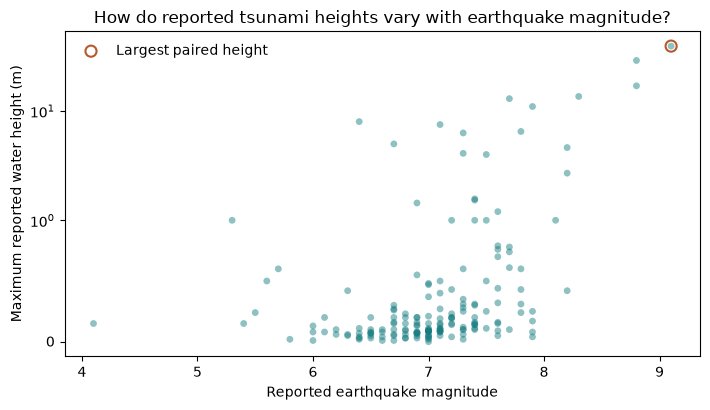

Spearman ρ = 0.471 (positive sample rank association). Heights still vary at similar magnitudes.
The largest paired height is 39.26 m. The plotted and primary results retain it.
A sensitivity check omitting only that point gives ρ = 0.462.


In [21]:
earthquake_only = noaa["cause_code"].eq(1).fillna(False)
eligible = earthquake_only & ~noaa["event_validity"].isin([-1, 0])
pairs = pd.DataFrame({"magnitude": magnitude, "height": height}).loc[eligible].dropna()
print(f"NOAA cause code 1 appears in {earthquake_only.sum():,} selected observations. "
      f"{eligible.sum():,} pass the validity filter and {len(pairs):,} have both finite measurements.")


def spearman(paired_values):
    ranks = paired_values.rank(method="average")
    return ranks["magnitude"].corr(ranks["height"])


rho = None
if len(pairs) < 10 or pairs.nunique().min() < 2:
    print("This selection needs at least ten complete pairs and variation in both fields for the exploratory analysis.")
else:
    rho = spearman(pairs)
    largest_pair = pairs.loc[pairs["height"].idxmax()]
    remaining = pairs.drop(index=largest_pair.name)
    rho_without_largest = spearman(remaining) if remaining.nunique().min() >= 2 else None

    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.scatter(pairs["magnitude"], pairs["height"], s=24, alpha=0.48, color=teal, edgecolors="none")
    ax.scatter(largest_pair["magnitude"], largest_pair["height"], s=64, facecolors="none",
               edgecolors=orange, linewidths=1.5, label="Largest paired height")
    ax.set_yscale("symlog", linthresh=1)
    ax.set(xlabel="Reported earthquake magnitude", ylabel="Maximum reported water height (m)",
           title="How do reported tsunami heights vary with earthquake magnitude?")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

    direction = "positive" if rho > 0 else "negative" if rho < 0 else "zero"
    print(f"Spearman ρ = {rho:.3f} ({direction} sample rank association). Heights still vary at similar magnitudes.")
    print(f"The largest paired height is {largest_pair['height']:.2f} m. The plotted and primary results retain it.")
    if rho_without_largest is None:
        print("Omitting it leaves a constant field, so the sensitivity check has no coefficient.")
    else:
        print(f"A sensitivity check omitting only that point gives ρ = {rho_without_largest:.3f}.")

## 7. Missing Values, Earthquake Statistics and Depth Outliers Across Topics

Sections 2–6 focus on NOAA tsunamis. This section applies the same completeness and outlier checks to every Silver topic, using the current version of each `(source, external_id)` key: the latest source revision for earthquakes and bulletins, then the latest Silver processing time (PDF pp. 23, 26 and 31).

**Text length and language.** The Workshop 3 guide suggests text-length and language indicators for text corpora. They do not apply here: the only text fields are short catalog labels (`place`, `location_name`, CAP event names) in English, with no free text to measure.

In [ ]:
lineage = {"bronze_file", "locator", "bronze_manifest", "silver_processed_at", "content_hash", "snapshot_path"}
revision = {"earthquakes": "source_updated_at", "tsunami_bulletins": "atom_updated_at"}


def current_topic(topic):
    """All Silver snapshots of a topic, keeping the current version of each source key."""
    batches = [pd.read_parquet(path, dtype_backend="numpy_nullable").assign(snapshot_path=path.as_uri())
               for path in silver_files[topic]]
    batches = [batch for batch in batches if not batch.empty]
    if not batches:
        return pd.DataFrame()
    frame = pd.concat(batches, ignore_index=True)
    order = [column for column in (revision.get(topic), "silver_processed_at", "snapshot_path") if column in frame]
    return (frame.sort_values(order, kind="stable", na_position="first")
            .drop_duplicates(key, keep="last").reset_index(drop=True))


current = {topic: current_topic(topic) for topic in ("earthquakes", "tsunami_events", "tsunami_bulletins")}

null_rows = []
for topic, frame in current.items():
    fields = [column for column in frame.columns if column not in lineage and column not in key
              and not column.endswith("_outlier")]
    for source, group in frame.groupby("source"):
        for field in fields:
            values = group[field]
            missing = values.isna()
            if pd.api.types.is_float_dtype(values):
                missing |= ~np.isfinite(values.astype(float).fillna(np.nan))
            null_rows.append((topic, source_names.get(source, source), field, int(missing.sum()), len(group)))

nulls = pd.DataFrame(null_rows, columns=["Topic", "Source", "Field", "Missing", "Observations"])
nulls["Missing (%)"] = (100 * nulls["Missing"] / nulls["Observations"]).round(2)
print(f"{len(nulls)} field checks across {len(current)} topics; "
      f"{nulls['Missing'].gt(0).sum()} fields have missing values.")
display(nulls.loc[nulls["Missing"].gt(0)].sort_values("Missing (%)", ascending=False).reset_index(drop=True))

In [ ]:
earthquakes = current["earthquakes"]
if earthquakes.empty:
    print("No earthquake observations in the selected Silver snapshots.")
else:
    measures = earthquakes.assign(Source=earthquakes["source"].replace(source_names))
    for field, label in (("magnitude", "Magnitude"), ("depth_km", "Depth (km)")):
        stats = measures.groupby("Source")[field].describe().round(2)
        display(Markdown(f"**{label}** by source"))
        display(stats)

    # Depth outliers: Silver's IQR flag, recomputed here per source as a check
    depth_rows = []
    for source, group in earthquakes.groupby("source"):
        depth = group["depth_km"].astype(float).dropna()
        q1, q3 = depth.quantile([0.25, 0.75])
        upper = q3 + 1.5 * (q3 - q1)
        recomputed = int((depth > upper).sum() + (depth < q1 - 1.5 * (q3 - q1)).sum())
        flagged = int(group["depth_km_iqr_outlier"].fillna(False).sum()) if "depth_km_iqr_outlier" in group else None
        depth_rows.append((source_names.get(source, source), len(depth), round(q1, 1), round(q3, 1),
                           round(upper, 1), recomputed, flagged, round(depth.max(), 1)))
    depth_outliers = pd.DataFrame(depth_rows, columns=["Source", "Depths", "Q1 (km)", "Q3 (km)", "Upper fence (km)",
                                                       "Outliers (recomputed)", "Outliers (Silver flag)", "Max (km)"])
    display(depth_outliers)

    fig, ax = plt.subplots(figsize=(8, 3.5))
    names, groups = zip(*[(name, group["depth_km"].astype(float).dropna()) for name, group in measures.groupby("Source")])
    try:
        ax.boxplot(groups, orientation="horizontal", flierprops={"markersize": 3})  # matplotlib >= 3.10
    except TypeError:
        ax.boxplot(groups, vert=False, flierprops={"markersize": 3})
    ax.set_yticks(range(1, len(names) + 1), names)
    ax.set(xlabel="Depth (km)", title="Earthquake depth by source (current observations)")
    ax.axvline(70, color=orange, linestyle="--", linewidth=1)
    ax.text(72, 1.5, "70 km: shallow limit of the relevance level", color=orange, fontsize=8)
    plt.tight_layout()
    plt.show()
    print("The Silver flags were computed per processing batch, so their counts can differ from this recomputation "
          "over the current observations of each source.")
    print("Deep earthquakes are flagged by the IQR rule because most catalog events are shallow; they are valid "
          "values, kept for review, and the relevance level treats depth separately (deeper than 300 km is at most LOW).")

## 8. Findings, Hypotheses and Limitations

Relate each finding to its evidence and the decision it supports (PDF pp. 14 and 52). The source cohorts reflect the configured catalog selection and saved feed windows.

In [22]:
findings = []

if not noaa.empty and missing_time.any():
    findings.append(
        "**What can we infer from partial clocks?** A recorded date supports yearly analysis. "
        "For event identification, the available clock components bound a search interval. Wider intervals "
        "leave more uncertainty about which earthquake matches, so partial NOAA observations require review."
    )

if not heights.empty and heights.mean() > heights.median():
    findings.append(
        "**What describes a typical height?** The mean exceeds the median and the upper measurements "
        "extend beyond the middle half. Use the median and IQR to describe the centre and spread, and retain "
        "the extreme values for individual review."
    )
    highest = heights.nlargest(4)
    if len(highest) == 4 and noaa.loc[highest.index, "cause_code"].eq(8).fillna(False).all():
        findings.append(
            "**Hypothesis to investigate.** The four largest reported heights carry the landslide cause code. "
            "The upper tail may differ by documented cause. Checking that hypothesis would require comparable "
            "measurements and case-level evidence on how the heights were reported."
        )

if rho is not None:
    findings.append(
        "**How should the magnitude–height association be used?** The paired records describe a rank association "
        "within the earthquake-only subset. Differences at similar magnitudes and the complete-case selection "
        "limit generalization. Causal attribution and prediction require separate evidence."
    )

if findings:
    display(Markdown("\n\n".join(f"- {finding}" for finding in findings)))
else:
    print("The selected files contain insufficient NOAA observations for the exploratory findings.")

- **What can we infer from partial clocks?** A recorded date supports yearly analysis. For event identification, the available clock components bound a search interval. Wider intervals leave more uncertainty about which earthquake matches, so partial NOAA observations require review.

- **What describes a typical height?** The mean exceeds the median and the upper measurements extend beyond the middle half. Use the median and IQR to describe the centre and spread, and retain the extreme values for individual review.

- **Hypothesis to investigate.** The four largest reported heights carry the landslide cause code. The upper tail may differ by documented cause. Checking that hypothesis would require comparable measurements and case-level evidence on how the heights were reported.

- **How should the magnitude–height association be used?** The paired records describe a rank association within the earthquake-only subset. Differences at similar magnitudes and the complete-case selection limit generalization. Causal attribution and prediction require separate evidence.